In [10]:
import pandas as pd

# Replace with your file path
df = pd.read_csv("/Users/niklasmelton/Downloads/twitter.csv")          # expects columns named 'latitude' and 'longitude'
sub_df = df.sample(frac=0.01, random_state=42,replace=False)

# Optionally reset row indices in the new DataFrame
sub_df = sub_df.reset_index(drop=True)
lat = sub_df["latitude"].to_numpy()
lon = sub_df["longitude"].to_numpy()


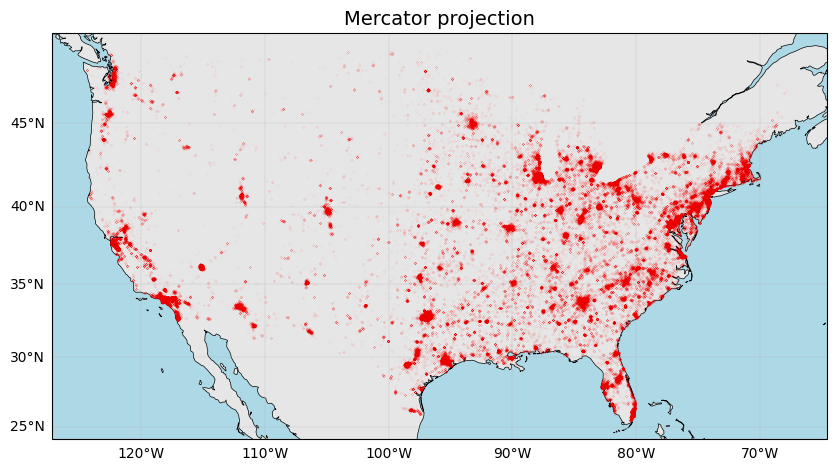

In [12]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

def plot_points(projection, title):
    fig = plt.figure(figsize=(10, 10))
    ax  = plt.axes(projection=projection)
    ax.set_title(title, fontsize=14)

    # Add minimal map features
    ax.add_feature(cfeature.LAND,  facecolor="0.9")
    ax.add_feature(cfeature.OCEAN, facecolor="lightblue")
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

    # Scatter the points (transform tells Cartopy the source CRS is plain lat/lon)
    ax.scatter(lon, lat,
               color="red", s=0.001,
               transform=ccrs.PlateCarree(),
               zorder=5)

    # Optionally draw gridlines
    gl = ax.gridlines(draw_labels=True, linewidth=0.2)
    gl.top_labels   = gl.right_labels = False  # keep plot tidy

    plt.show()

# 3‑a  Globe view (orthographic, centred on the prime meridian):
# plot_points(ccrs.Orthographic(central_longitude=0, central_latitude=20),
#             "Orthographic (globe)")

# 3‑b  Mercator view:
plot_points(ccrs.Mercator(), "Mercator projection")


In [13]:
!pip install cgal

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.5/10.5 MB 14.5 MB/s eta 0:00:00 0:00:01

[notice] A new release of pip is available: 24.2 -> 25.0.1
[notice] To update, run: /Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip


In [15]:
from CGAL.CGAL_Kernel import Point_2
from CGAL.CGAL_Triangulation_2 import Triangulation_2
from CGAL.CGAL_Triangulation_2 import Triangulation_2_Vertex_circulator
from CGAL.CGAL_Triangulation_2 import Triangulation_2_Vertex_handle

points=[]
points.append( Point_2(1,0) )
points.append( Point_2(3,2) )
points.append( Point_2(4,5) )
points.append( Point_2(9,8) )
points.append( Point_2(7,4) )
points.append( Point_2(5,2) )
points.append( Point_2(6,3) )
points.append( Point_2(10,1) )
  
t=Triangulation_2()
t.insert(points)

vc = t.incident_vertices(t.infinite_vertex())

if vc.hasNext():
  done = vc.next();
  iter=Triangulation_2_Vertex_handle()
  while(1):
    iter=vc.next()
    print(iter.point())
    if iter == done:
      break

1 0
4 5
9 8
10 1
